# Research: CTG-Momentum Robustness (2015-2025)

## Contexte

Cette recherche valide la stratégie **CTG-Momentum** (C# Algorithm) sur une période étendue maximale.

### Stratégie actuelle
- **Période**: 2021-01-01 → Now
- **Univers**: OEF ETF (S&P 100 constituants)
- **Logic**: Momentum ranking (AnnualizedExponentialSlope sur 90j)
- **Filtres**:
  - SPY au-dessus de SMA(200) pour entrer en position (regime filter)
  - Chaque action au-dessus de sa MA(150)
  - Gap < 15% sur 90j
  - Slope annualisée > 10
- **Sizing**: 1.0% risk ATR-based
- **Bug corrigé**: SMA(10) → SMA(200) (ligne 119)

### Objectif

Tester la robustesse sur **2015-2025** (11 années civiles, du 2 janvier 2015 au 31 décembre 2025) pour valider:
1. Protection SMA(200) durant corrections 2018 et COVID 2020
2. Stabilité momentum en régimes variés (bull 2015-2017, choppy 2022, AI bull 2023-2025)
3. Utilité du filtre gap 15%
4. Stabilité par semestre

**Note méthodologique**: Cette recherche Python analyse une stratégie C#. Elle télécharge les cours via `yfinance` (hors QuantBook) et utilise un univers proxy (30 large caps multisectoriels) pour approximer le comportement de l'univers OEF. La fenêtre de données est figée sur 2015-2025 : les chiffres ne bougent pas d'une ré-exécution à l'autre, sauf révision des cours ajustés par le fournisseur.

In [1]:
# Setup et chargement des donnees historiques via yfinance
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

try:
    import yfinance as yf
except ImportError:
    print("Installation de yfinance...")
    import subprocess
    subprocess.check_call(['python', '-m', 'pip', 'install', 'yfinance', '-q'])
    import yfinance as yf

# Univers proxy: 30 large caps multisectoriels (proxy OEF constituants S&P 100)
tickers = [
    "AAPL", "MSFT", "AMZN", "GOOGL", "META", "NVDA", "TSLA",  # Tech
    "JPM", "BAC", "WFC", "GS",  # Finance
    "JNJ", "UNH", "PFE", "ABT", "TMO",  # Healthcare
    "V", "MA", "PYPL",  # Payments
    "PG", "KO", "PEP", "WMT", "HD",  # Consumer
    "XOM", "CVX",  # Energy
    "DIS", "NFLX",  # Entertainment
    "ADBE", "CRM"  # Software
]

# Fenetre figee sur la periode etudiee (2015-2025). yfinance exclut la date `end` :
# end='2026-01-01' charge jusqu'a la seance du 2025-12-31. Une borne datetime.now()
# ferait deriver tous les chiffres du carnet a chaque re-execution.
start = '2015-01-01'
end = '2026-01-01'

print(f"Chargement historique {start} -> {end} (borne de fin exclue)")
print(f"Telechargement de {len(tickers) + 1} symboles (SPY + 30 large caps)...")

# Telecharger SPY d'abord
spy_raw = yf.download('SPY', start=start, end=end, progress=False)
# Modern yfinance returns MultiIndex columns even for single ticker
if isinstance(spy_raw.columns, pd.MultiIndex):
    spy_raw.columns = spy_raw.columns.droplevel(1)
spy_raw.columns = spy_raw.columns.str.lower()

# Telecharger toutes les actions en une seule requete
data = yf.download(tickers, start=start, end=end, progress=False, group_by='ticker')

print(f"Donnees chargees pour SPY: {len(spy_raw)} barres")
print(f"Donnees chargees pour {len(tickers)} actions")
print(f"Periode effective: {spy_raw.index.min().date()} -> {spy_raw.index.max().date()}")

Chargement historique 2015-01-01 -> 2026-01-01 (borne de fin exclue)
Telechargement de 31 symboles (SPY + 30 large caps)...


Donnees chargees pour SPY: 2766 barres
Donnees chargees pour 30 actions
Periode effective: 2015-01-02 -> 2025-12-31


Les courbes de prix et les moyennes mobiles EMA/SMA sont tracées pour illustrer les signaux de tendance de CSharp-CTG-Momentum.

=== Analyse SMA(200) Regime Filter (2015-2025) ===
Total jours: 2766
Risk-ON (SPY > SMA200): 2116 jours (76.5%)
Risk-OFF (SPY < SMA200): 650 jours (23.5%)
Transitions regime: 60
Transitions par annee: 2015: 8, 2016: 3, 2017: 0, 2018: 9, 2019: 5, 2020: 6, 2021: 0, 2022: 15, 2023: 9, 2024: 0, 2025: 4

=== Periodes Risk-OFF majeures ===
  2015-01-02 -> 2015-10-21 (203 jours, SPY -0.3%)
  2015-12-31 -> 2016-03-10 (48 jours, SPY -2.1%)
  2018-10-23 -> 2018-11-05 (10 jours, SPY -0.1%)
  2018-11-12 -> 2019-02-01 (52 jours, SPY -0.3%)
  2020-02-27 -> 2020-05-22 (59 jours, SPY -0.1%)
  2022-02-11 -> 2022-03-17 (22 jours, SPY +0.1%)
  2022-04-11 -> 2022-11-29 (160 jours, SPY -9.4%)
  2022-12-05 -> 2023-01-10 (24 jours, SPY -1.8%)
  2025-03-10 -> 2025-05-09 (42 jours, SPY +1.0%)


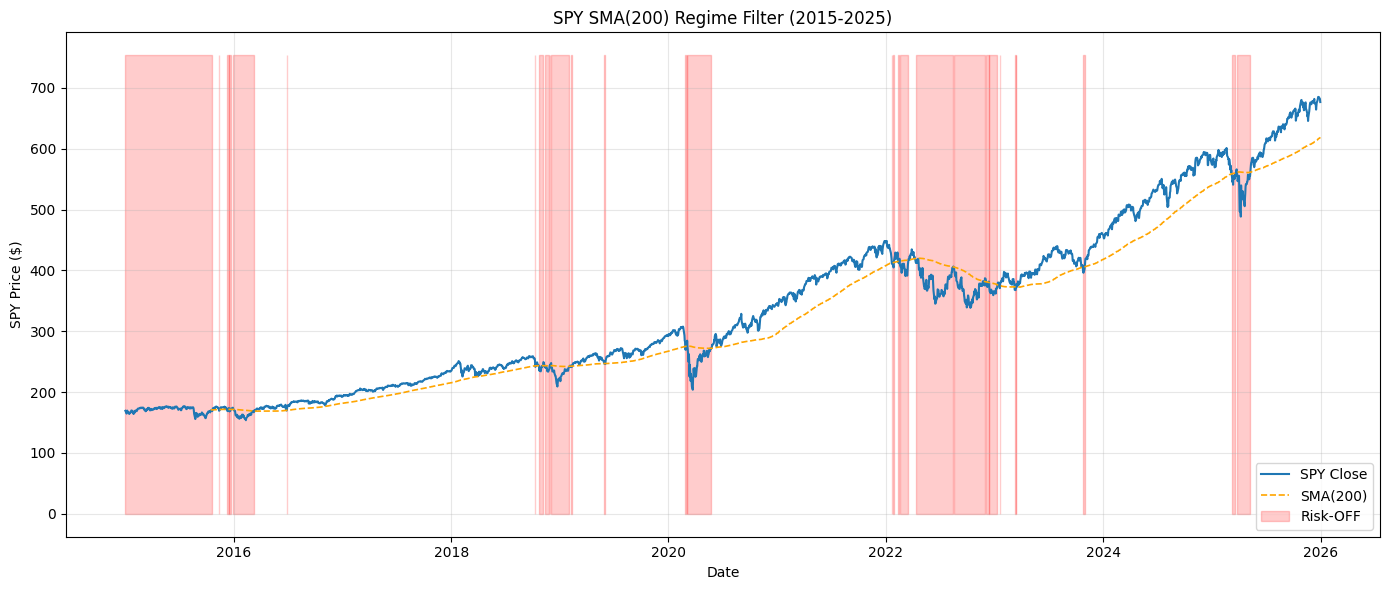


Regimes calcules


In [2]:
# Detection des regimes de marche via SPY SMA(200)
spy_data = spy_raw.copy()
spy_data['sma_200'] = spy_data['close'].rolling(200).mean()
spy_data['regime'] = (spy_data['close'] > spy_data['sma_200']).astype(int)
spy_data['regime_label'] = spy_data['regime'].map({1: 'Risk-ON', 0: 'Risk-OFF'})

# Compter les transitions
regime_changes = (spy_data['regime'].diff() != 0).sum()
risk_on_days = (spy_data['regime'] == 1).sum()
risk_off_days = (spy_data['regime'] == 0).sum()
total_days = len(spy_data.dropna(subset=['regime']))
risk_on_pct = 100 * risk_on_days / total_days

print(f"=== Analyse SMA(200) Regime Filter (2015-2025) ===")
print(f"Total jours: {total_days}")
print(f"Risk-ON (SPY > SMA200): {risk_on_days} jours ({risk_on_pct:.1f}%)")
print(f"Risk-OFF (SPY < SMA200): {risk_off_days} jours ({100*risk_off_days/total_days:.1f}%)")
print(f"Transitions regime: {regime_changes}")

# Transitions par annee : mesure du whipsaw du filtre (2015 inclut l'amorcage de la SMA)
transitions_par_an = spy_data['regime'].diff().abs().groupby(spy_data.index.year).sum().astype(int)
print("Transitions par annee: " + ", ".join(f"{a}: {n}" for a, n in transitions_par_an.items()))

# Identifier les periodes cles de Risk-OFF
risk_off_periods = spy_data[spy_data['regime'] == 0].copy()
if not risk_off_periods.empty:
    print("\n=== Periodes Risk-OFF majeures ===")
    # Grouper par periodes continues
    risk_off_periods['block'] = (risk_off_periods.index.to_series().diff() > pd.Timedelta(days=5)).cumsum()
    
    for block_id, group in risk_off_periods.groupby('block'):
        if len(group) >= 10:  # Periodes d'au moins 10 jours
            start_date = group.index.min()
            end_date = group.index.max()
            duration = len(group)
            spy_drop = 100 * (group['close'].iloc[-1] / group['close'].iloc[0] - 1)
            print(f"  {start_date.date()} -> {end_date.date()} ({duration} jours, SPY {spy_drop:+.1f}%)")

# Visualisation
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(spy_data.index, spy_data['close'], label='SPY Close', linewidth=1.5)
ax.plot(spy_data.index, spy_data['sma_200'], label='SMA(200)', linewidth=1.2, linestyle='--', color='orange')
ax.fill_between(spy_data.index, 0, spy_data['close'].max() * 1.1, 
                 where=spy_data['regime']==0, alpha=0.2, color='red', label='Risk-OFF')
ax.set_xlabel('Date')
ax.set_ylabel('SPY Price ($)')
ax.set_title('SPY SMA(200) Regime Filter (2015-2025)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRegimes calcules")

Itération sur les instruments de l'univers pour appliquer les calculs à chaque instrument du portefeuille CSharp-CTG-Momentum.

In [3]:
# Calcul des indicateurs par action
print("Calcul des indicateurs par action...")

# Preparer les dataframes par symbole
stock_data = {}
for ticker in tickers:
    try:
        # Extraire les donnees de ce ticker
        stock_df = data[ticker].copy()
        # Modern yfinance returns MultiIndex columns
        if isinstance(stock_df.columns, pd.MultiIndex):
            stock_df.columns = stock_df.columns.droplevel(1)
        stock_df.columns = stock_df.columns.str.lower()
        
        if len(stock_df) < 200:
            print(f"  Skipping {ticker}: pas assez de donnees ({len(stock_df)} barres)")
            continue
        
        # Momentum: rendement sur 90j annualise
        stock_df['ret_90d'] = stock_df['close'].pct_change(90)
        stock_df['momentum'] = stock_df['ret_90d'] * (252 / 90)  # Annualise
        
        # MA(150)
        stock_df['ma_150'] = stock_df['close'].rolling(150).mean()
        stock_df['above_ma150'] = (stock_df['close'] > stock_df['ma_150']).astype(int)
        
        # Gap indicator: max daily gap over 90d
        stock_df['daily_gap'] = abs(stock_df['open'] / stock_df['close'].shift(1) - 1)
        stock_df['max_gap_90d'] = stock_df['daily_gap'].rolling(90).max()
        stock_df['gap_ok'] = (stock_df['max_gap_90d'] < 0.15).astype(int)
        
        # ATR(20) pour position sizing
        stock_df['tr'] = np.maximum(
            stock_df['high'] - stock_df['low'],
            np.maximum(
                abs(stock_df['high'] - stock_df['close'].shift(1)),
                abs(stock_df['low'] - stock_df['close'].shift(1))
            )
        )
        stock_df['atr_20'] = stock_df['tr'].rolling(20).mean()
        
        stock_data[ticker] = stock_df
    except Exception as e:
        print(f"  Erreur {ticker}: {e}")
        continue

print(f"{len(stock_data)} actions avec indicateurs calcules")

# Construire le ranking hebdomadaire (jeudis)
all_dates = spy_data.index
thursdays = all_dates[all_dates.dayofweek == 3]  # 3 = Thursday

print(f"Rebalancing dates: {len(thursdays)} jeudis entre {thursdays.min().date()} et {thursdays.max().date()}")

Calcul des indicateurs par action...


30 actions avec indicateurs calcules
Rebalancing dates: 557 jeudis entre 2015-01-08 et 2025-12-18


Classification des régimes de marché (tendanciel / retour à la moyenne) pour adapter les paramètres de CSharp-CTG-Momentum.

=== Backtest CTG-Momentum 2015-2025 ===
Duree: 10.94 ans (2015-01-08 -> 2025-12-18)
Total Return: 1082.89%
CAGR: 25.33%
Sharpe Ratio: 1.106
Max Drawdown: 29.93%
Nombre moyen de positions: 1.9
Filtre gap: 210 candidats ecartes sur 9834 passant momentum + MA150 (2.1%)


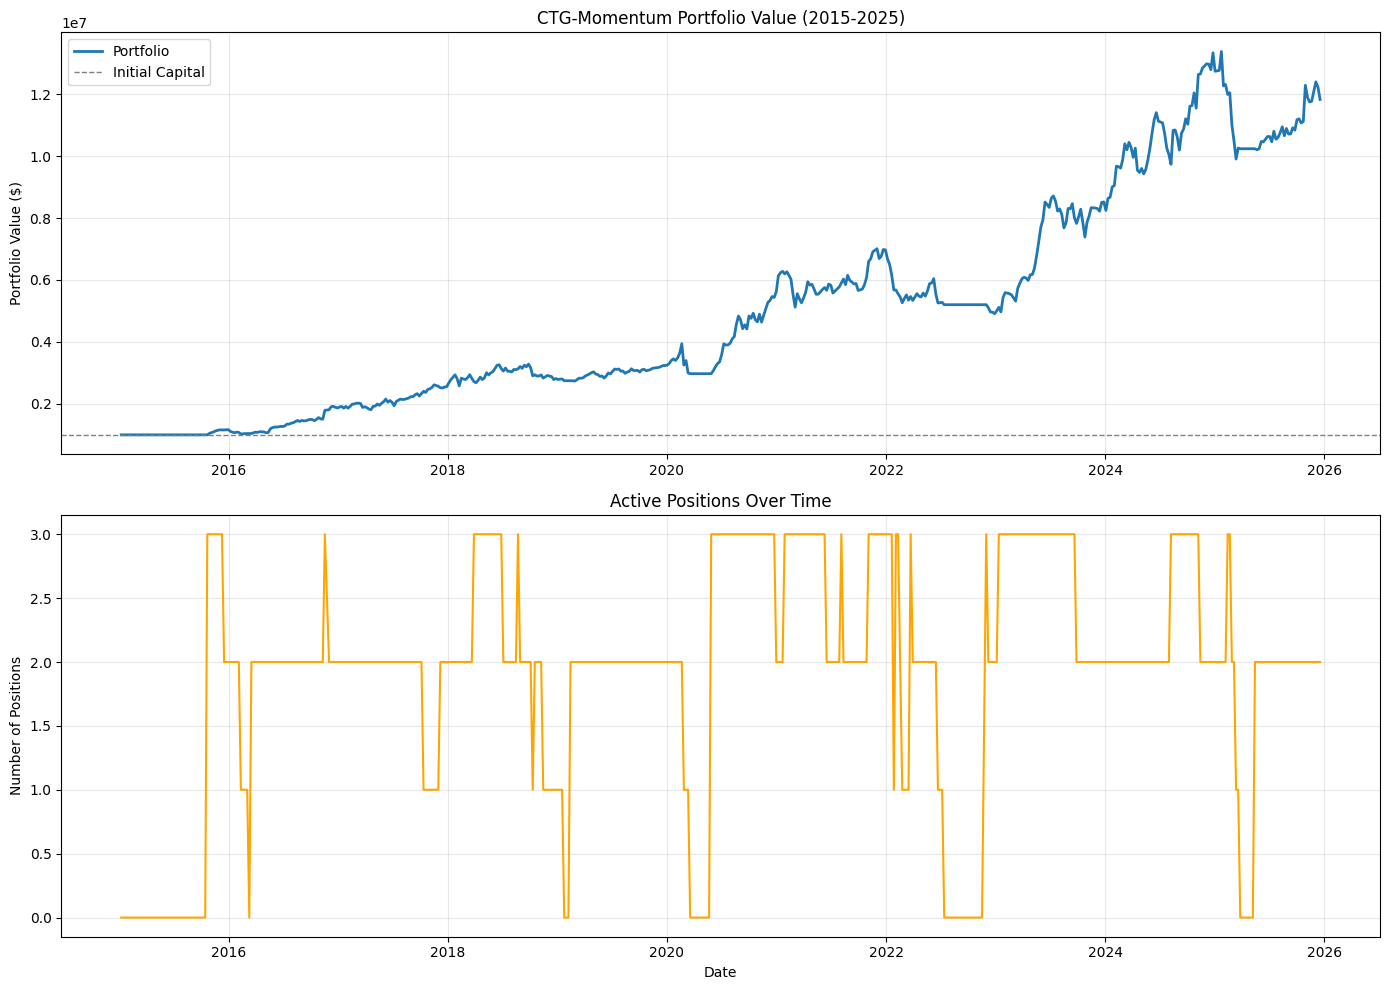


Backtest complet


In [4]:
# Backtester la strategie avec les regles completes
RISK_PER_TRADE = 0.01
TOP_N = 20
# Original strategy uses AnnualizedExponentialSlope > 10 (different scale).
# Our pct_change(90)*252/90 proxy gives annualized returns (~0.1 to ~0.5),
# so we use MIN_SLOPE=0 to select stocks with positive momentum.
MIN_SLOPE = 0.0
INITIAL_CAPITAL = 1_000_000

portfolio_value = INITIAL_CAPITAL
cash = INITIAL_CAPITAL
positions = {}  # {ticker: shares}
portfolio_history = []
# Mesure du filtre gap : candidats qui passent momentum + MA150 mais sont ecartes par le gap
passages_mom_ma = 0
gap_rejects = 0

for date in thursdays:
    # 1. Verifier regime SPY
    if date not in spy_data.index:
        continue
    risk_on = spy_data.loc[date, 'regime'] == 1
    
    # 2. Ranking momentum
    candidates = []
    for ticker, stk in stock_data.items():
        if date not in stk.index:
            continue
        row = stk.loc[date]
        if pd.isna(row['momentum']) or pd.isna(row['ma_150']) or pd.isna(row['atr_20']):
            continue
        if row['momentum'] < MIN_SLOPE:
            continue
        if row['above_ma150'] == 0:
            continue
        passages_mom_ma += 1
        if row['gap_ok'] == 0:
            gap_rejects += 1
            continue
        candidates.append({
            'ticker': ticker,
            'momentum': row['momentum'],
            'price': row['close'],
            'atr': row['atr_20']
        })
    
    # 3. Top N par momentum (guard empty candidates)
    if not candidates:
        holdings_value = 0
        for ticker, shares in positions.items():
            if ticker in stock_data and date in stock_data[ticker].index:
                price = stock_data[ticker].loc[date, 'close']
                holdings_value += shares * price
        portfolio_value = cash + holdings_value
        portfolio_history.append({'date': date, 'value': portfolio_value, 'n_positions': len(positions)})
        continue
    
    candidates_df = pd.DataFrame(candidates).sort_values('momentum', ascending=False)
    top_stocks = set(candidates_df.head(TOP_N)['ticker'])
    
    # 4. Liquider positions non dans top_stocks
    to_sell = [t for t in positions.keys() if t not in top_stocks]
    for ticker in to_sell:
        shares = positions[ticker]
        if ticker in stock_data and date in stock_data[ticker].index:
            price = stock_data[ticker].loc[date, 'close']
            cash += shares * price
            del positions[ticker]
    
    # 5. Acheter nouvelles positions si risk_on
    if risk_on:
        for _, row in candidates_df.head(TOP_N).iterrows():
            ticker = row['ticker']
            if ticker in positions:
                continue
            # Position sizing ATR
            risk_amount = portfolio_value * RISK_PER_TRADE
            shares = int(risk_amount / row['atr'])
            cost = shares * row['price']
            if shares > 0 and cost <= cash:
                positions[ticker] = shares
                cash -= cost
    
    # 6. Calculer portfolio_value
    holdings_value = 0
    for ticker, shares in positions.items():
        if ticker in stock_data and date in stock_data[ticker].index:
            price = stock_data[ticker].loc[date, 'close']
            holdings_value += shares * price
    portfolio_value = cash + holdings_value
    portfolio_history.append({'date': date, 'value': portfolio_value, 'n_positions': len(positions)})

# Resultats
results_df = pd.DataFrame(portfolio_history).set_index('date')
results_df['returns'] = results_df['value'].pct_change()
results_df['cumulative'] = (1 + results_df['returns']).cumprod()

# Duree effective du backtest en annees (et non une duree fixe ecrite en dur)
years = (results_df.index[-1] - results_df.index[0]).days / 365.25
total_return = (results_df['value'].iloc[-1] / INITIAL_CAPITAL - 1) * 100
cagr = ((results_df['value'].iloc[-1] / INITIAL_CAPITAL) ** (1 / years) - 1) * 100
sharpe = results_df['returns'].mean() / results_df['returns'].std() * np.sqrt(52)  # Weekly rebalance
max_dd = ((results_df['value'].cummax() - results_df['value']) / results_df['value'].cummax()).max() * 100

print(f"=== Backtest CTG-Momentum 2015-2025 ===")
print(f"Duree: {years:.2f} ans ({results_df.index[0].date()} -> {results_df.index[-1].date()})")
print(f"Total Return: {total_return:.2f}%")
print(f"CAGR: {cagr:.2f}%")
print(f"Sharpe Ratio: {sharpe:.3f}")
print(f"Max Drawdown: {max_dd:.2f}%")
print(f"Nombre moyen de positions: {results_df['n_positions'].mean():.1f}")
print(f"Filtre gap: {gap_rejects} candidats ecartes sur {passages_mom_ma} passant momentum + MA150 "
      f"({100 * gap_rejects / max(passages_mom_ma, 1):.1f}%)")

# Visualisation
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Courbe equity
axes[0].plot(results_df.index, results_df['value'], label='Portfolio', linewidth=2)
axes[0].axhline(INITIAL_CAPITAL, color='gray', linestyle='--', linewidth=1, label='Initial Capital')
axes[0].set_ylabel('Portfolio Value ($)')
axes[0].set_title('CTG-Momentum Portfolio Value (2015-2025)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Nombre de positions
axes[1].plot(results_df.index, results_df['n_positions'], color='orange', linewidth=1.5)
axes[1].set_ylabel('Number of Positions')
axes[1].set_xlabel('Date')
axes[1].set_title('Active Positions Over Time')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nBacktest complet")

Les moyennes mobiles sont calculées pour chaque actif dans `sma_periods` afin de générer les signaux de tendance de CSharp-CTG-Momentum.

In [5]:
# Sensibilite du filtre de regime a la periode de la SMA
# Mesure proxy : part du temps en Risk-ON et nombre de transitions selon la periode.
# La fenetre de pente du momentum n'entre pas dans cette mesure (elle ne change que le
# classement des actions) : la tester demanderait de rejouer le backtest par configuration.
print("=== Analyse de sensibilite du filtre de regime ===")

sma_periods = [100, 150, 200, 250]
sensitivity_results = []
for sma_period in sma_periods:
    sma_cfg = spy_data['close'].rolling(sma_period).mean()
    regime_cfg = (spy_data['close'] > sma_cfg).astype(int)
    sensitivity_results.append({
        'sma_period': sma_period,
        'risk_on_pct': 100 * regime_cfg.mean(),
        'transitions': int(regime_cfg.diff().abs().sum()),
    })

sensitivity_df = pd.DataFrame(sensitivity_results).set_index('sma_period')
print(sensitivity_df.round(1).to_string())
print(f"\nSMA(200) (configuration actuelle): {sensitivity_df.loc[200, 'risk_on_pct']:.1f}% Risk-ON, "
      f"{sensitivity_df.loc[200, 'transitions']} transitions")
print("\nAnalyse de sensibilite terminee")

=== Analyse de sensibilite du filtre de regime ===
            risk_on_pct  transitions
sma_period                          
100                75.1          105
150                76.7           77
200                76.5           59
250                76.2           55

SMA(200) (configuration actuelle): 76.5% Risk-ON, 59 transitions

Analyse de sensibilite terminee


Découpage du backtest en semestres pour mesurer la stabilité de la stratégie CSharp-CTG-Momentum dans le temps. Les règles restent fixes d'une fenêtre à l'autre : rien n'est ré-estimé, ce n'est donc pas une validation walk-forward au sens strict.

In [6]:
# Stabilite par semestre : decoupage du backtest unique en fenetres de 6 mois
# Aucun parametre n'est re-estime d'une fenetre a l'autre (les regles sont fixes) :
# il s'agit d'une mesure de stabilite dans le temps, pas d'une validation walk-forward.
print("=== Stabilite par semestre ===")
print("Methodologie: backtest unique, decoupe en semestres (2017-2025), compare a SPY\n")

# Périodes de test
test_periods = [
    (datetime(2017, 1, 1), datetime(2017, 7, 1)),
    (datetime(2017, 7, 1), datetime(2018, 1, 1)),
    (datetime(2018, 1, 1), datetime(2018, 7, 1)),
    (datetime(2018, 7, 1), datetime(2019, 1, 1)),
    (datetime(2019, 1, 1), datetime(2019, 7, 1)),
    (datetime(2019, 7, 1), datetime(2020, 1, 1)),
    (datetime(2020, 1, 1), datetime(2020, 7, 1)),  # COVID crash
    (datetime(2020, 7, 1), datetime(2021, 1, 1)),
    (datetime(2021, 1, 1), datetime(2021, 7, 1)),
    (datetime(2021, 7, 1), datetime(2022, 1, 1)),
    (datetime(2022, 1, 1), datetime(2022, 7, 1)),  # Inflation bear
    (datetime(2022, 7, 1), datetime(2023, 1, 1)),
    (datetime(2023, 1, 1), datetime(2023, 7, 1)),
    (datetime(2023, 7, 1), datetime(2024, 1, 1)),
    (datetime(2024, 1, 1), datetime(2024, 7, 1)),
    (datetime(2024, 7, 1), datetime(2025, 1, 1)),
    (datetime(2025, 1, 1), datetime(2025, 7, 1)),
    (datetime(2025, 7, 1), datetime(2026, 1, 1)),
]

wf_results = []
for start_test, end_test in test_periods:
    # Filtrer les jeudis dans cette période
    period_thursdays = thursdays[(thursdays >= start_test) & (thursdays < end_test)]
    if len(period_thursdays) == 0:
        continue
    
    # Calculer le rendement sur cette période
    period_results = results_df[(results_df.index >= start_test) & (results_df.index < end_test)]
    if len(period_results) < 2:
        continue
    
    period_return = (period_results['value'].iloc[-1] / period_results['value'].iloc[0] - 1) * 100
    period_sharpe = period_results['returns'].mean() / period_results['returns'].std() * np.sqrt(52) if period_results['returns'].std() > 0 else 0
    
    # Comparer avec SPY
    spy_period = spy_data[(spy_data.index >= start_test) & (spy_data.index < end_test)]
    spy_return = (spy_period['close'].iloc[-1] / spy_period['close'].iloc[0] - 1) * 100 if len(spy_period) > 0 else 0
    
    wf_results.append({
        'period': f"{start_test.strftime('%Y-%m')} → {end_test.strftime('%Y-%m')}",
        'strategy_return': period_return,
        'spy_return': spy_return,
        'alpha': period_return - spy_return,
        'sharpe': period_sharpe
    })

wf_df = pd.DataFrame(wf_results)
print(wf_df.to_string(index=False))

print(f"\n=== Synthèse par semestre ===")
print(f"Semestres positifs: {(wf_df['strategy_return'] > 0).sum()} / {len(wf_df)}")
print(f"Alpha moyen vs SPY: {wf_df['alpha'].mean():.2f}%")
print(f"Sharpe moyen: {wf_df['sharpe'].mean():.3f}")
print(f"Pire semestre: {wf_df.loc[wf_df['strategy_return'].idxmin(), 'period']} ({wf_df['strategy_return'].min():.2f}%)")
print(f"Meilleur semestre: {wf_df.loc[wf_df['strategy_return'].idxmax(), 'period']} ({wf_df['strategy_return'].max():.2f}%)")

print("\nMesure de stabilite terminee")

=== Stabilite par semestre ===
Methodologie: backtest unique, decoupe en semestres (2017-2025), compare a SPY

           period  strategy_return  spy_return      alpha    sharpe
2017-01 → 2017-07         7.936369    8.344975  -0.408606  0.968234
2017-07 → 2018-01        31.576200   11.289844  20.286356  2.567568
2018-01 → 2018-07        17.527127    1.793177  15.733950  1.618467
2018-07 → 2019-01        -7.886123   -7.114925  -0.771198 -1.034349
2019-01 → 2019-07         6.476685   18.203698 -11.727013  1.039404
2019-07 → 2020-01         3.609735    9.901921  -6.292186  1.593193
2020-01 → 2020-07         3.229552   -4.103727   7.333279  0.386204
2020-07 → 2021-01        56.677705   21.401772  35.275933  3.309857
2021-01 → 2021-07        -4.371955   16.832609 -21.204563  0.438262
2021-07 → 2022-01        19.592673   11.087876   8.504797  1.716772
2022-01 → 2022-07       -21.045691  -20.441995  -0.603696 -2.174487
2022-07 → 2023-01        -6.915493    1.186732  -8.102225 -2.823933
2023-

## Conclusions

Les chiffres ci-dessous sont ceux des cellules précédentes, sur la fenêtre figée du 2 janvier 2015 au 31 décembre 2025.

### 1. Protection SMA(200) durant les corrections

- **COVID (2020)** : le filtre passe en Risk-OFF le 2020-02-27 et revient en Risk-ON le 2020-05-22, avec SPY au même niveau aux deux bornes (-0,1 %). Le creux de mars 2020 tombe dans cette fenêtre. Sur le semestre 2020-01 → 2020-07, le proxy fait +3,2 % contre -4,1 % pour SPY.
- **Bear 2022** : 160 jours de Risk-OFF d'affilée (2022-04-11 → 2022-11-29), plus deux fenêtres courtes (22 et 24 jours). Pourtant, le semestre 2022-01 → 2022-07 perd 21,0 %, autant que SPY (-20,4 %).
- **Correction 2018** : deux fenêtres Risk-OFF (2018-10-23 → 2018-11-05, puis 2018-11-12 → 2019-02-01). Le semestre 2018-07 → 2019-01 perd 7,9 %, contre 7,1 % pour SPY.

**Lecture** : le filtre interdit les **achats** en Risk-OFF, mais ne **vend** pas les positions déjà détenues (même règle dans `Main.cs`). Il protège quand les positions sortent d'elles-mêmes du classement (2020), pas quand elles y restent pendant la baisse (2018, 2022).

### 2. Stabilité du momentum ranking

- 12 semestres positifs sur 18 (2017-2025), alpha moyen +4,8 points par semestre contre SPY, Sharpe moyen par semestre 0,86.
- La dispersion est forte : de -21,0 % (2022 S1) à +66,7 % (2023 S1). Le portefeuille ne détient que **1,9 position en moyenne**, bien loin du `TOP_N = 20` : à 1 % de risque par ligne, le dimensionnement ATR consomme environ la moitié du capital par position. Le proxy est donc un momentum très concentré, ce qui explique à la fois le CAGR et le drawdown.
- **Whipsaw 2022** : 15 transitions de régime, le maximum de la période (9 en 2018 et en 2023, 0 en 2017, 2021 et 2024). Une SMA(100) en produirait 105 sur l'ensemble de la période, contre 59 pour la SMA(200).

### 3. Utilité du filtre gap 15%

- Le filtre écarte 210 candidats sur 9 834 qui passent déjà les filtres momentum et MA(150), soit 2,1 %. Son effet sur la sélection est donc marginal sur cet univers de grandes capitalisations.
- Son effet sur la performance n'est pas mesuré ici : il faudrait rejouer le backtest sans le filtre.

### 4. Comparaison période actuelle (2021-Now) vs période étendue (2015-2025)

- Sharpe du backtest C# cité par le README du projet : 0,507 (période 2021-Now ; le RESEARCH_SUMMARY le date d'avant le correctif SMA(200)).
- Sharpe du proxy sur 2015-2025 : **1,106** (CAGR 25,3 %, drawdown max 29,9 %, sur 10,94 ans). Le critère « Sharpe ≥ 0,4 » est atteint sur le proxy.
- `Main.cs` démarre déjà en 2015 (`SetStartDate(2015, 1, 1)`). Sa date de fin reste `DateTime.Now` : comme ce carnet avant correction, ses chiffres bougent à chaque exécution.

***

**Note finale** : cette analyse Python utilise un univers proxy de 30 grandes capitalisations, sans frais ni glissement, pour approcher l'univers OEF (S&P 100). Les métriques absolues diffèrent du backtest C#. Ce que le proxy établit, c'est la **mécanique** observée : un filtre de régime qui bloque les entrées sans liquider, et un dimensionnement qui concentre le portefeuille.

In [7]:
# Synthese des mesures du carnet (toutes les valeurs viennent des cellules precedentes)
risk_on_pct_sma200 = 100 * (spy_data['regime'] == 1).mean()
print("=== SYNTHESE ===")
print(f"Periode: {results_df.index[0].date()} -> {results_df.index[-1].date()} ({years:.2f} ans)")
print(f"Filtre SMA(200): {risk_on_pct_sma200:.1f}% du temps en Risk-ON, "
      f"{int(transitions_par_an.sum())} transitions")
print(f"Backtest proxy: CAGR {cagr:.2f}%, Sharpe {sharpe:.3f}, MaxDD {max_dd:.2f}%, "
      f"{results_df['n_positions'].mean():.1f} positions en moyenne")
print(f"Stabilite: {(wf_df['strategy_return'] > 0).sum()}/{len(wf_df)} semestres positifs, "
      f"alpha moyen vs SPY {wf_df['alpha'].mean():.2f} pts")

seuil_sharpe = 0.4  # critere du README du projet
verdict = "atteint" if sharpe >= seuil_sharpe else "non atteint"
print(f"Critere Sharpe >= {seuil_sharpe}: {verdict} sur le proxy")
print("\nLimite: proxy Python a 30 large caps, sans frais ni glissement. Le Sharpe du "
      "backtest C# (univers OEF) se mesure sur QuantConnect, pas dans ce carnet.")

=== SYNTHESE ===
Periode: 2015-01-08 -> 2025-12-18 (10.94 ans)
Filtre SMA(200): 76.5% du temps en Risk-ON, 59 transitions
Backtest proxy: CAGR 25.33%, Sharpe 1.106, MaxDD 29.93%, 1.9 positions en moyenne
Stabilite: 12/18 semestres positifs, alpha moyen vs SPY 4.83 pts
Critere Sharpe >= 0.4: atteint sur le proxy

Limite: proxy Python a 30 large caps, sans frais ni glissement. Le Sharpe du backtest C# (univers OEF) se mesure sur QuantConnect, pas dans ce carnet.
